# MS-DSA-NET — демонстрация: инференс, лоссы, ошибки модели


**Честность показа:** пациент с ФКД показывается моделью своего фолда (она его не видела); пациенты без ФКД — из отложенных (их не видела ни одна модель).

## 0. Настройка

In [1]:
import os, sys, time, json, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
FSLDIR, VENV_BIN = Path.home() / "fsl", Path(sys.executable).parent
os.environ.update(FSLDIR=str(FSLDIR), FSLOUTPUTTYPE="NIFTI_GZ")
_p = [p for p in os.environ["PATH"].split(":") if p and p not in (str(VENV_BIN), f"{FSLDIR}/bin", f"{FSLDIR}/share/fsl/bin")]
os.environ["PATH"] = ":".join([str(VENV_BIN)] + _p + [f"{FSLDIR}/share/fsl/bin", f"{FSLDIR}/bin"])

PROJ    = Path.home() / "projects/mri/ms_dsa_net"
REPO    = PROJ / "MS-DSA-NET"
MNI     = REPO / "inputs/MNI152_T1_1mm.nii.gz"
DEPLOY  = PROJ / "deploy"
GPU_ID  = 1
DEMO_THR = None         

os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"; os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU_ID)
for p in (Path.cwd(), PROJ):
    if (p / "msdsa_lib.py").exists() and str(p) not in sys.path: sys.path.insert(0, str(p))
import msdsa_lib as ml
import numpy as np, pandas as pd, nibabel as nib, torch
import matplotlib.pyplot as plt
from scipy import ndimage
from monai.inferers import sliding_window_inference
sys.path.insert(0, str(REPO))
from networks2 import MS_DSA_NET
torch.set_num_threads(4)
device = torch.device("cuda")

CFG = json.load(open(DEPLOY / "config.json"))
THR = DEMO_THR or CFG["post"]["thr"]
POST = ml.Post(thr=THR, brain=True, dilate_mm=3, min_vox=100)
print(f"Порог {THR} | GPU {GPU_ID}: {torch.cuda.get_device_name(0)} | свободно {torch.cuda.mem_get_info()[0]/2**30:.1f} ГБ")

Порог 0.9 | GPU 1: NVIDIA RTX A4000 | свободно 6.1 ГБ


## 0.1. Модели и данные

In [2]:
PATCH = (128, 128, 128)
def build():
    return MS_DSA_NET(spatial_dims=3, in_channels=2, out_channels=2, img_size=list(PATCH), feature_size=16, pos_embed=True,
                      project_size=64, sa_type="parallel", norm_name="instance",
                      act_name=("leakyrelu", {"inplace": True, "negative_slope": 0.01}), res_block=True, bias=False, dropout_rate=0.1)
def load(path):
    sd = torch.load(path, map_location="cpu"); sd = sd.get("model", sd.get("state_dict", sd))
    m = build(); m.load_state_dict({k.replace("module.", "", 1): v for k, v in sd.items()}); return m.to(device).eval()
def run_sw_of(m):
    def f(x, sw):
        with torch.no_grad(), torch.autocast("cuda"):
            return sliding_window_inference(x, PATCH, sw, m, overlap=0.25)
    return f

orig = load(REPO / "pretrained/model.pth")
folds = [load(DEPLOY / f) for f in CFG["models"]]
NYUL = ml.Nyul(np.load(DEPLOY / CFG["nyul_ref"]))
INFER = {"исходная": ml.make_infer(run_sw_of(orig), device, 4),
         "итоговая (ансамбль 2b)": ml.make_ensemble_infer([run_sw_of(m) for m in folds], device, 4, tta=True)}
INFER_FOLD = [ml.make_infer(run_sw_of(m), device, 4, tta=True) for m in folds]

SPL = json.load(open(PROJ / "checkpoints/stage2b_splits.json")); FOLDS = SPL["folds"]
meta = pd.read_csv(PROJ / "data/ideas_meta/Metadata_Release_Anon.csv"); meta["sub"] = "sub-" + meta["ID"].astype(str)
meta = meta.drop_duplicates("sub").set_index("sub")
mask_fn = lambda s: (lambda p: p if p.exists() else None)(PROJ / "data/ideas_masks/masks" / s[4:] / f"{s[4:]}_MaskInRawData.nii.gz")
IDEAS = ml.Dataset("IDEAS", "ds005602", PROJ / "data/ds005602", PROJ / "work", PROJ / "outputs", gt_space="t1")
IDEAS.files = ml.index_with_local_masks(ml.s3_index(IDEAS.s3_id, IDEAS.data_dir / "_s3_index.txt"), meta.index.tolist(), mask_fn)
UHB = ml.Dataset("UHB", "ds004199", PROJ / "data/ds004199", PROJ / "work_uhb", PROJ / "outputs_uhb", gt_space="flair")
_k = ml.s3_index(UHB.s3_id, UHB.data_dir / "_s3_index.txt")
UHB.files = {**ml.index_without_masks(_k), **ml.index_with_masks_in_s3(_k)}

FCD = sorted(FOLDS)
NEG = [(IDEAS, s) for s in SPL["neg_test"] if (IDEAS.fsl(s) / "flair_reg.nii.gz").exists()] + \
      [(UHB, s) for s in SPL["hc_test"] if (UHB.fsl(s) / "flair_reg.nii.gz").exists()]
flair_mm = lambda ds, s: max(nib.load(ml._local(ds, ds.files[s]["flair"])).header.get_zooms()[:3])
import re
def subtype(s):
    m = re.search(r"(?i)type\s*(III?[ABD]?)", str(meta.loc[s, "OP MEMO"])) if s in meta.index else None
    return m.group(1).upper() if m else "?"
MNI_ARR = nib.load(MNI).get_fdata(dtype=np.float32); BRAIN_REF = MNI_ARR > np.percentile(MNI_ARR[MNI_ARR > 0], 10)
print(f"Модели загружены: исходная + {len(folds)} фолдов | ФКД {len(FCD)} | без ФКД (отложенные) {len(NEG)}")

Модели загружены: исходная + 5 фолдов | ФКД 34 | без ФКД (отложенные) 45


## 0.2. Функции показа

In [3]:
def post_mask(prob, brain, p=None):
    """Маска после постобработки (как в метриках и в deploy)."""
    p = p or POST
    pr = np.where(ndimage.binary_dilation(brain, iterations=p.dilate_mm), prob, 0) if (p.brain and brain is not None) else prob
    lab, n = ndimage.label(pr >= p.thr, structure=ml.STRUCT)
    if not n: return np.zeros(prob.shape, bool)
    ids = np.arange(1, n + 1); sizes = np.asarray(ndimage.sum_labels(lab > 0, lab, ids))
    keep = ids[sizes >= p.min_vox]
    return np.isin(lab, keep)

def view(flair, overlays, gt=None, center=None, title=""):
    """3 проекции; overlays: {подпись: маска}; жёлтый контур — эталонная маска."""
    if center is None:
        src = gt if (gt is not None and gt.any()) else next((m for m in overlays.values() if m.any()), None)
        center = np.round(ndimage.center_of_mass(src)).astype(int) if src is not None else np.array(flair.shape) // 2
    x, y, z = center
    fig, ax = plt.subplots(len(overlays), 3, figsize=(11, 3.6 * len(overlays)), squeeze=False)
    for r, (name, m) in enumerate(overlays.items()):
        for c, (img, gm, mm, lbl) in enumerate([(flair[:, :, z], None if gt is None else gt[:, :, z], m[:, :, z], f"аксиальный z={z}"),
                                                 (flair[:, y, :], None if gt is None else gt[:, y, :], m[:, y, :], f"корональный y={y}"),
                                                 (flair[x, :, :], None if gt is None else gt[x, :, :], m[x, :, :], f"сагиттальный x={x}")]):
            a = ax[r, c]; a.imshow(np.rot90(img), cmap="gray", vmin=0, vmax=1)
            if mm.any(): a.imshow(np.rot90(np.ma.masked_where(~mm, mm)), cmap="autumn", alpha=0.6, vmin=0, vmax=1)
            if gm is not None and gm.any(): a.contour(np.rot90(gm), colors="yellow", linewidths=1)
            a.set_title(f"{name} — {lbl}" if c == 0 else lbl, fontsize=9); a.axis("off")
    fig.suptitle(title, fontsize=11); plt.tight_layout(); plt.show()

def load_case(ds, sub, variant):
    x, gt, brain, aff = ml.load_arrays(ds, sub)
    pf = ds.pred(variant) / f"{sub}_prob.nii.gz"
    prob = nib.load(pf).get_fdata(dtype=np.float32) if pf.exists() else None
    return x[1], gt, brain, aff, prob

# Часть 1. Живой инференс

In [4]:
def live(ds, sub, model="итоговая (ансамбль 2b)", fresh_fsl=False, show=True):
    root = PROJ / "demo_runs"
    D = ml.Dataset(f"{ds.name}_demo", ds.s3_id, ds.data_dir, (root / "work") if fresh_fsl else ds.work_dir,
                   root / ds.name, gt_space=ds.gt_space, files={sub: ds.files[sub]})
    variant = "live_" + "".join(ch for ch in model if ch.isalnum())[:20]
    old = D.pred(variant) / f"{sub}_prob.nii.gz"
    if old.exists(): old.unlink()                                       # считать заново, без кэша
    infer = INFER_FOLD[FOLDS[sub]] if model == "модель своего фолда" else INFER[model]
    harm = None if model == "исходная" else NYUL
    t0 = time.time()
    r = ml.run_pipeline(D, [sub], infer=infer, harmonizer=harm, variant=variant, mni=MNI, n_fsl=1, progress=False)
    if r["failures"]: print("ошибка:", r["failures"]); return
    tl = r["timeline"].set_index("stage")
    qc = ml.input_qc(ml._local(ds, ds.files[sub]["t1"]), ml._local(ds, ds.files[sub]["flair"]),
                     D.fsl(sub) / "t1_reg.nii.gz", MNI_ARR, BRAIN_REF, CFG["qc_rules"])
    img = nib.load(D.pred(variant) / f"{sub}_prob.nii.gz"); prob = img.get_fdata(dtype=np.float32)
    brain = nib.load(D.ref / f"{sub}_brain.nii.gz").get_fdata() > 0
    gtf = D.ref / f"{sub}_gt.nii.gz"; gt = nib.load(gtf).get_fdata() > 0 if gtf.exists() else None
    cands = ml.cluster_table(prob, brain, POST, img.affine, top=3)
    dur = lambda st: tl.loc[st, "end"] - tl.loc[st, "start"] if st in tl.index else 0
    print(f"⏱ всего {time.time()-t0:.0f} с | FSL {dur('fsl'):.0f} с | подготовка {dur('load'):.1f} с | модель {dur('gpu'):.1f} с")
    print(("вход в норме" if qc["ok"] else "⚠️ " + "; ".join(qc["flags"])) +
          f" | T1 {qc['t1_mm']:.1f} мм, FLAIR {qc['flair_mm']:.1f} мм, корреляция с MNI {qc.get('mni_corr', float('nan')):.2f}")
    print(f"Кандидатов: {len(cands)}" + ("" if gt is None else " | эталонная маска — жёлтый контур"))
    display(cands)
    if show:
        x, _, _, _ = ml.load_arrays(D, sub)
        c = np.round(cands[["vx", "vy", "vz"]].values[0]).astype(int) if len(cands) else None
        view(x[1], {model: post_mask(prob, brain)}, gt, center=c if gt is None else None,
             title=f"{ds.name} {sub} — {model}, порог {THR}")
    return prob, brain, gt

### 1a. Человек без ФКД (отложенный, ни одна модель его не видела)

[IDEAS_demo/live_итоговаяансамбль2b] 1.8 мин | готово 1 | ошибок 0
⏱ всего 106 с | FSL 76 с | подготовка 1.5 с | модель 26.9 с
вход в норме | T1 1.2 мм, FLAIR 2.0 мм, корреляция с MNI 0.60
Кандидатов: 0 | эталонная маска — жёлтый контур


,peak_prob,volume_ml,x,y,z


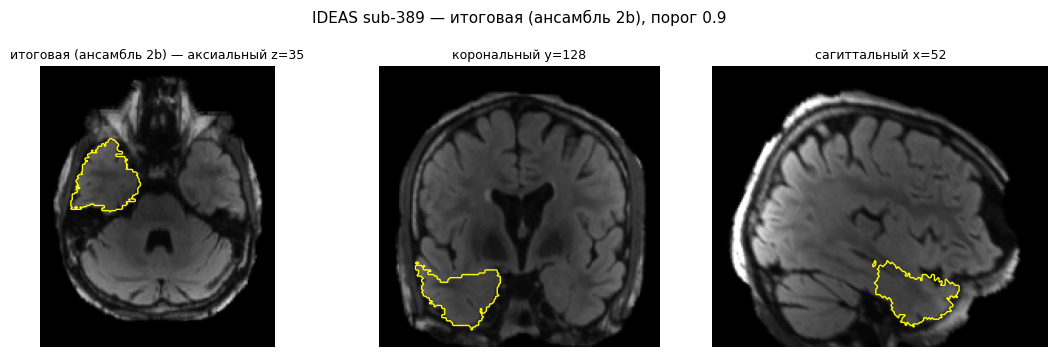

In [5]:
ds_neg, sub_neg = NEG[0]
_ = live(ds_neg, sub_neg, fresh_fsl=True)

### 1b. Пациент с ФКД — модель его фолда (не видела этого пациента).

sub-100 | подтип IIB | FLAIR 3.500127 мм | фолд 1
[IDEAS_demo/live_модельсвоегофолда] 0.1 мин | готово 1 | ошибок 0
⏱ всего 11 с | FSL 0 с | подготовка 1.6 с | модель 5.2 с
⚠️ FLAIR срезы 3.5 мм > 2.0 — чувствительность резко ниже | T1 1.1 мм, FLAIR 3.5 мм, корреляция с MNI 0.75
Кандидатов: 1 | эталонная маска — жёлтый контур


,peak_prob,volume_ml,vx,vy,vz,x,y,z
0,1.0,4.933,137.561,101.527,105.982,46.6,-24.5,34.0


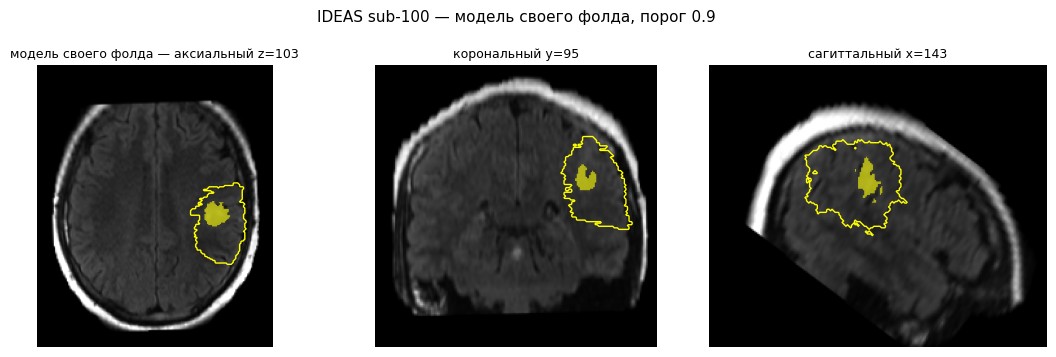

In [7]:
thin = [s for s in FCD if flair_mm(IDEAS, s) < 4.5]
sub_fcd = thin[0]
print(sub_fcd, "| подтип", subtype(sub_fcd), "| FLAIR", flair_mm(IDEAS, sub_fcd), "мм | фолд", FOLDS[sub_fcd])
_ = live(IDEAS, sub_fcd, model="модель своего фолда")

### 1c. Тот же пациент: исходная модель vs итоговая

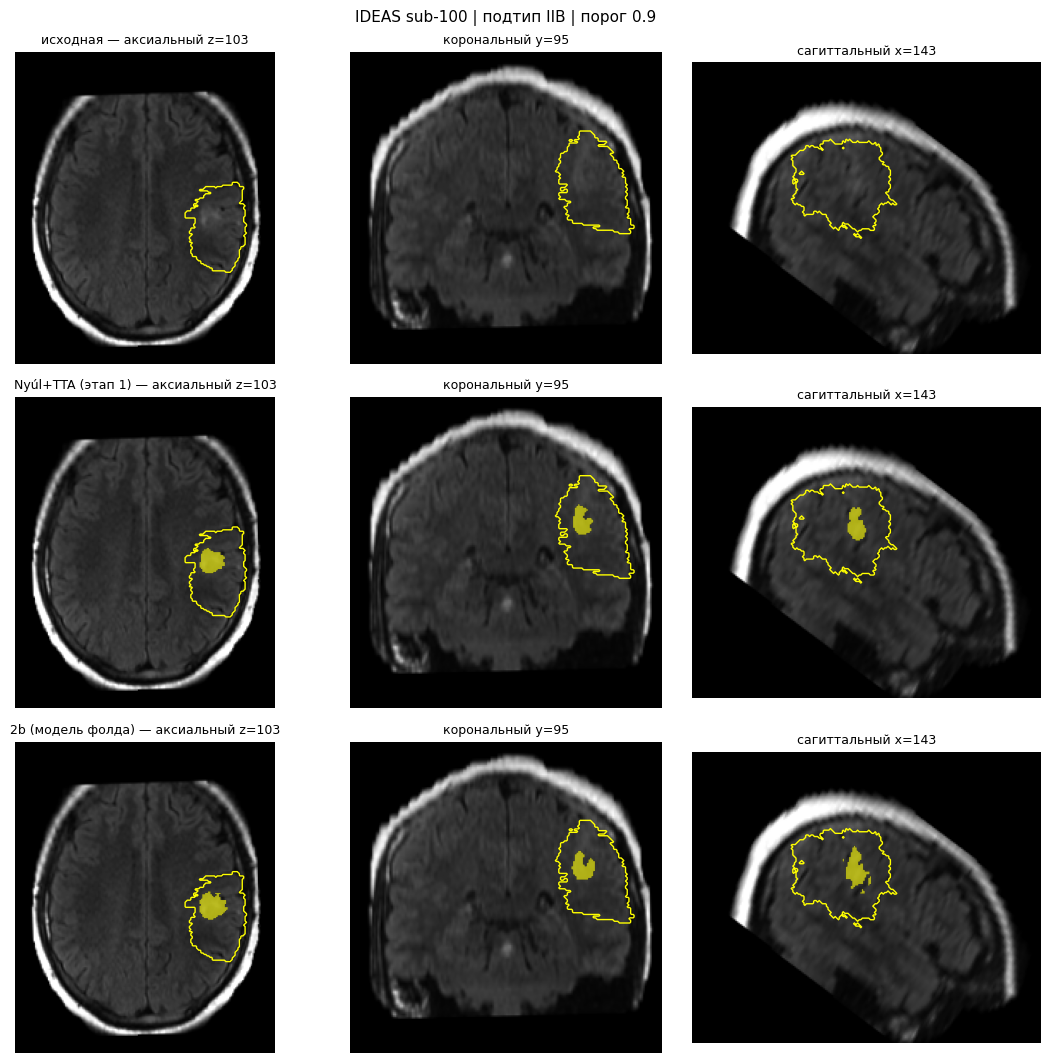

In [8]:
def compare(ds, sub, variants):
    fl, gt, brain, _, _ = load_case(ds, sub, "pred")
    ov = {}
    for name, v in variants.items():
        pf = ds.pred(v) / f"{sub}_prob.nii.gz"
        if pf.exists(): ov[name] = post_mask(nib.load(pf).get_fdata(dtype=np.float32), brain)
    view(fl, ov, gt, title=f"{ds.name} {sub} | подтип {subtype(sub) if ds is IDEAS else '-'} | порог {THR}")
compare(IDEAS, sub_fcd, {"исходная": "pred", "Nyúl+TTA (этап 1)": "nyul_tta", "2b (модель фолда)": "cv2b_nyul_tta"})

# Часть 2. Просмотрщик: любой пациент, любой вариант, листание срезов

In [9]:
import ipywidgets as W
from functools import lru_cache
VARIANTS = {"исходная": "pred", "Nyúl+TTA (этап 1)": "nyul_tta", "2b модель фолда / ансамбль": None}
CASES = {f"ФКД {s} ({subtype(s)}, FLAIR {flair_mm(IDEAS, s):.0f} мм)": (IDEAS, s) for s in FCD}
CASES.update({f"без ФКД {ds.name} {s}": (ds, s) for ds, s in NEG})

@lru_cache(maxsize=16)
def _case(key, vname):
    ds, s = CASES[key]
    v = VARIANTS[vname] or ("cv2b_nyul_tta" if key.startswith("ФКД") else "ens2b")
    if vname == "исходная" and ds is UHB: v = "base"
    fl, gt, brain, _, prob = load_case(ds, s, v)
    return fl, gt, (post_mask(prob, brain) if prob is not None else np.zeros(fl.shape, bool)), prob

def show_slice(case, variant, axis, pos):
    fl, gt, m, prob = _case(case, variant)
    ax_i = {"сагиттальный": 0, "корональный": 1, "аксиальный": 2}[axis]; pos = min(pos, fl.shape[ax_i] - 1)
    sl = {"аксиальный": np.s_[:, :, pos], "корональный": np.s_[:, pos, :], "сагиттальный": np.s_[pos, :, :]}[axis]
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(np.rot90(fl[sl]), cmap="gray", vmin=0, vmax=1)
    if m[sl].any(): ax[0].imshow(np.rot90(np.ma.masked_where(~m[sl], m[sl])), cmap="autumn", alpha=0.6)
    if gt is not None and gt[sl].any(): ax[0].contour(np.rot90(gt[sl]), colors="yellow", linewidths=1)
    ax[0].set_title("FLAIR + кандидаты (красный) + эталон (жёлтый)")
    if prob is not None:
        im = ax[1].imshow(np.rot90(prob[sl]), cmap="magma", vmin=0, vmax=1); plt.colorbar(im, ax=ax[1], fraction=0.046)
    ax[1].set_title("карта вероятности модели")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

W.interact(show_slice, case=W.Dropdown(options=list(CASES), description="Пациент", layout=W.Layout(width="520px")),
           variant=W.Dropdown(options=list(VARIANTS), description="Модель"),
           axis=W.ToggleButtons(options=["аксиальный", "корональный", "сагиттальный"]),
           pos=W.IntSlider(value=90, min=0, max=217, description="Срез", continuous_update=False));

interactive(children=(Dropdown(description='Пациент', layout=Layout(width='520px'), options=('ФКД sub-100 (IIB…

# Часть 3. Лоссы
**2a** (дообучение только на UHB): loss падает, а метрики валидации на 10 пациентах UHB скачут шагами 0.1 - выбор «лучшей эпохи» оказался шумом (лучшей стала 2-я).
**2b** (с IDEAS): три слагаемых. CE — по надёжному фону и точным маскам; Dice — точные маски UHB; MIL — «найди хоть что-то внутри резекции IDEAS».

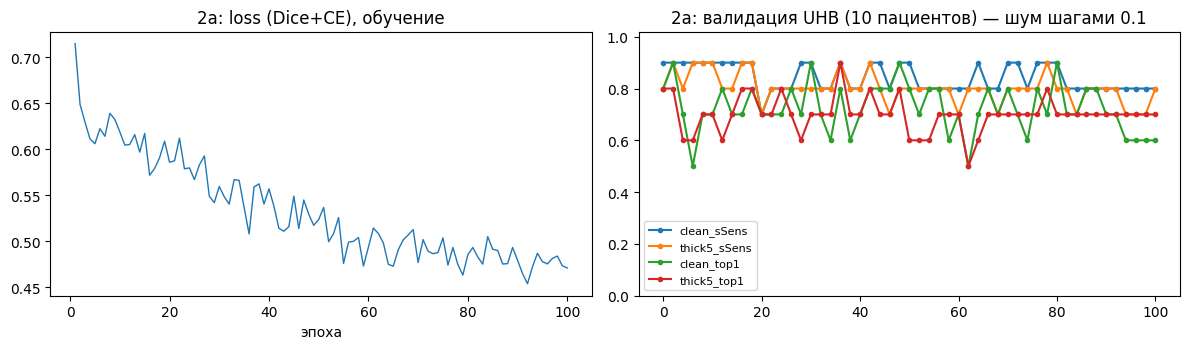

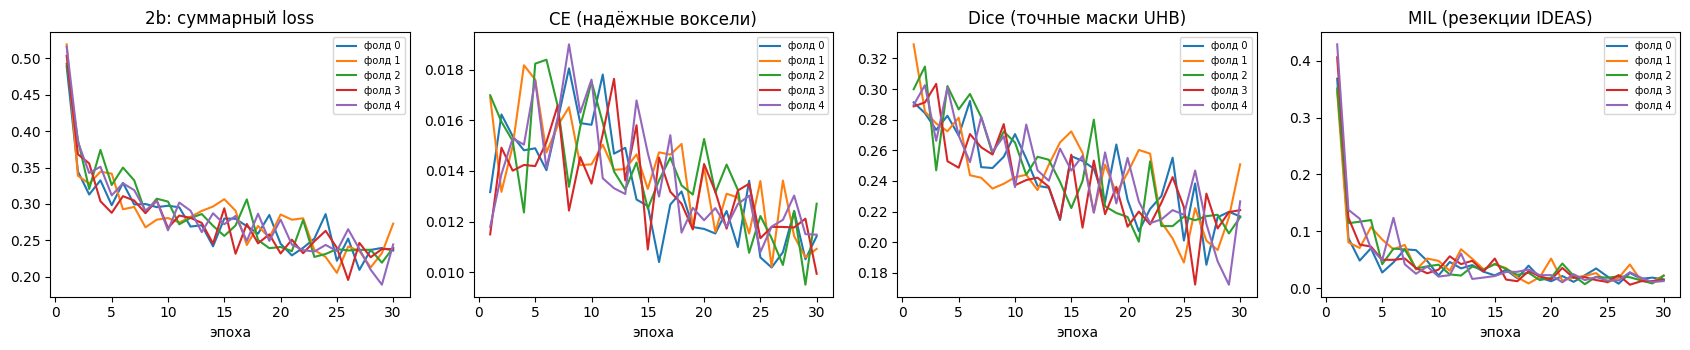

In [10]:
ck2a = PROJ / "checkpoints/stage2a/last.pt"
if ck2a.exists():
    lg = pd.DataFrame(torch.load(ck2a, map_location="cpu")["log"])
    v = lg.dropna(subset=["score"]) if "score" in lg else lg.iloc[:0]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(lg.epoch, lg.loss, "-", lw=1); ax[0].set_title("2a: loss (Dice+CE), обучение"); ax[0].set_xlabel("эпоха")
    for c in ("clean_sSens", "thick5_sSens", "clean_top1", "thick5_top1"):
        if c in v: ax[1].plot(v.epoch, v[c], "-o", ms=3, label=c)
    ax[1].set_title("2a: валидация UHB (10 пациентов) — шум шагами 0.1"); ax[1].set_ylim(0, 1.02); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for k in range(5):
    f = PROJ / f"checkpoints/stage2b/fold{k}/log.csv"
    if not f.exists(): continue
    lg = pd.read_csv(f)
    for a, c in zip(ax, ("loss", "ce", "dice", "mil")): a.plot(lg.epoch, lg[c], label=f"фолд {k}")
for a, t in zip(ax, ("2b: суммарный loss", "CE (надёжные воксели)", "Dice (точные маски UHB)", "MIL (резекции IDEAS)")):
    a.set_title(t); a.set_xlabel("эпоха"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

# Часть 4. Где модель ошибается
Для каждого пациента с ФКД — исход у итоговой схемы (модель своего фолда, порог как в deploy), толщина FLAIR, подтип, расстояние до маски у пропущенных.

In [11]:
P = [POST]
ev_fcd = ml.evaluate(IDEAS.pred("cv2b_nyul_tta"), IDEAS.ref, FCD, P)
ev_fcd["FLAIR_мм"] = ev_fcd["sub"].map(lambda s: flair_mm(IDEAS, s)); ev_fcd["подтип"] = ev_fcd["sub"].map(subtype)
ev_fcd["исход"] = np.select([ev_fcd.top_hit == 1, ev_fcd.top3_hit == 1, ev_fcd.detected == 1, ev_fcd.n_clusters == 0],
                            ["найден первым", "найден в топ-3", "найден, но не в топ-3", "нет кандидатов"], "только ложные кандидаты")
cols = ["sub", "исход", "подтип", "FLAIR_мм", "n_clusters", "nFPC", "dist_mm", "max_prob", "gt_ml"]
display(ev_fcd[cols].sort_values(["исход", "FLAIR_мм"]).reset_index(drop=True).round(2))
print("\nИсходы:", ev_fcd["исход"].value_counts().to_dict())
miss = ev_fcd[ev_fcd.detected == 0]
print(f"Пропущено {len(miss)} из {len(ev_fcd)}: FLAIR 5 мм — {int((miss.FLAIR_мм >= 4.5).sum())}, "
      f"FCD IIA — {int((miss.подтип == 'IIA').sum())}, «почти попал» (<15 мм) — {int((miss.dist_mm < 15).sum())}")

,sub,исход,подтип,FLAIR_мм,n_clusters,nFPC,dist_mm,max_prob,gt_ml
0,sub-187,найден в топ-3,IIB,3.0,2,1,NaN,1.00,63.36
1,sub-345,найден в топ-3,IIB,3.0,2,1,NaN,1.00,189.01
2,sub-116,найден первым,IIB,1.0,1,0,NaN,1.00,24.94
3,sub-304,найден первым,IIB,1.0,1,0,NaN,1.00,34.93
4,sub-83,найден первым,IIB,1.0,2,1,NaN,1.00,25.27
5,sub-411,найден первым,IIB,1.0,1,0,NaN,1.00,19.66
6,sub-172,найден первым,IIB,2.0,1,0,NaN,1.00,129.82
7,sub-86,найден первым,IIB,2.0,2,1,NaN,1.00,44.58
8,sub-313,найден первым,IIA,3.0,1,0,NaN,1.00,20.48
9,sub-166,найден первым,IIB,3.5,1,0,NaN,1.00,67.42



Исходы: {'найден первым': 17, 'нет кандидатов': 11, 'только ложные кандидаты': 4, 'найден в топ-3': 2}
Пропущено 15 из 34: FLAIR 5 мм — 11, FCD IIA — 4, «почти попал» (<15 мм) — 0


### 4a. Пропущенные очаги (жёлтый — маска резекции; красный — что нашла модель)

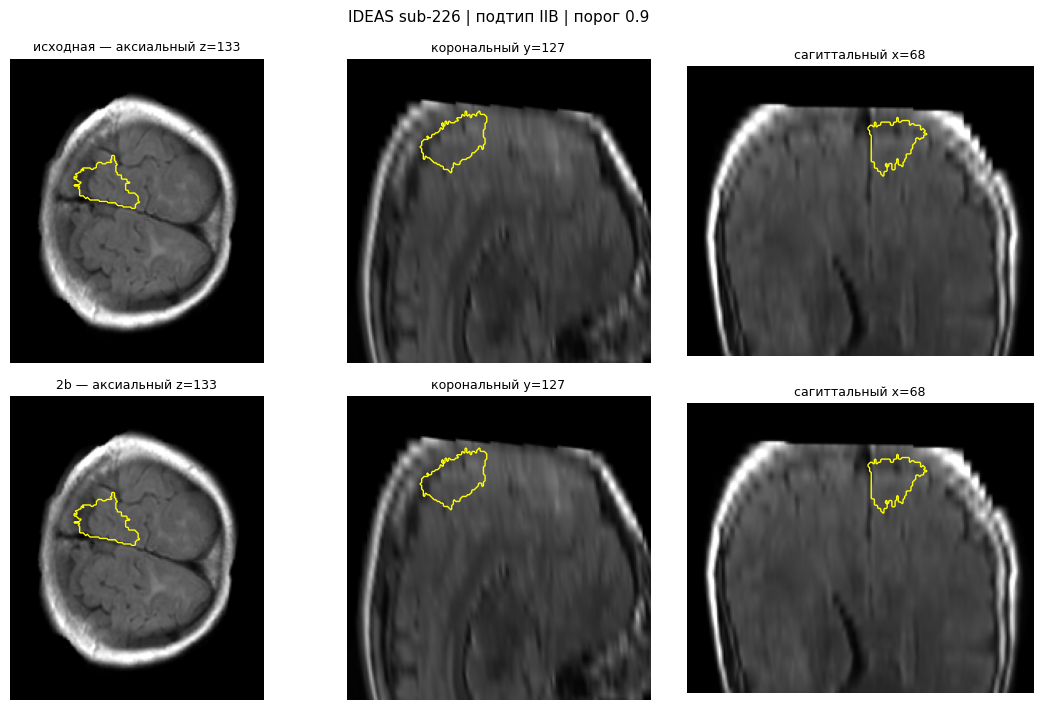

sub-226: подтип IIB, FLAIR 5.0 мм, ближайший кандидат в 24 мм от маски, макс. вероятность в мозге 1.00


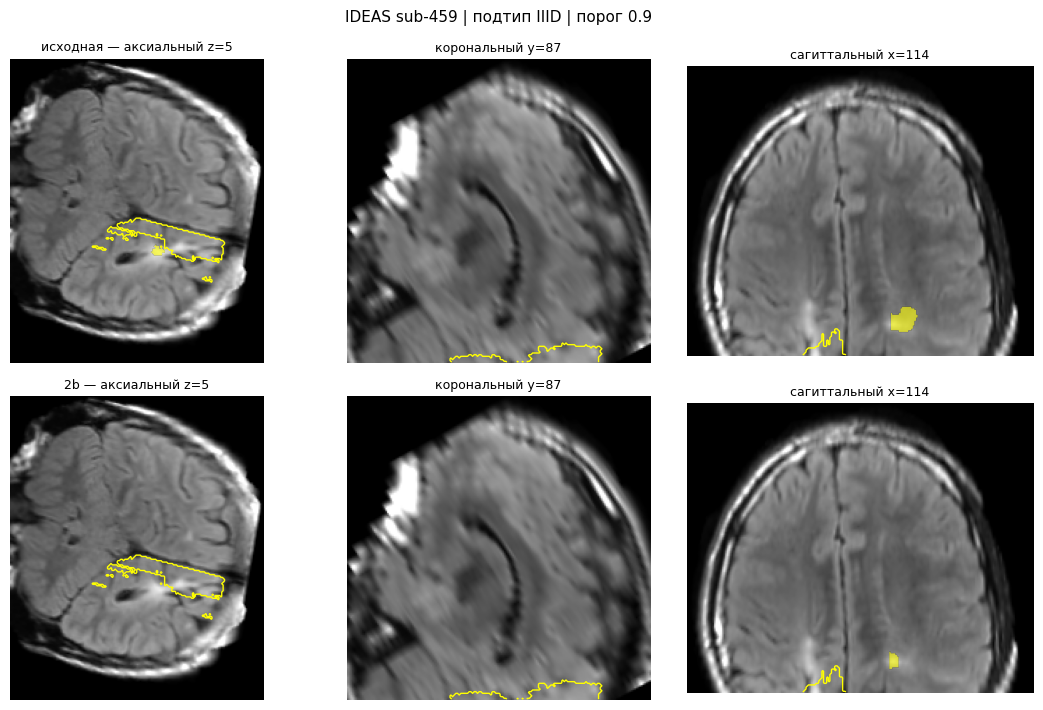

sub-459: подтип IIID, FLAIR 5.0 мм, ближайший кандидат в 29 мм от маски, макс. вероятность в мозге 1.00


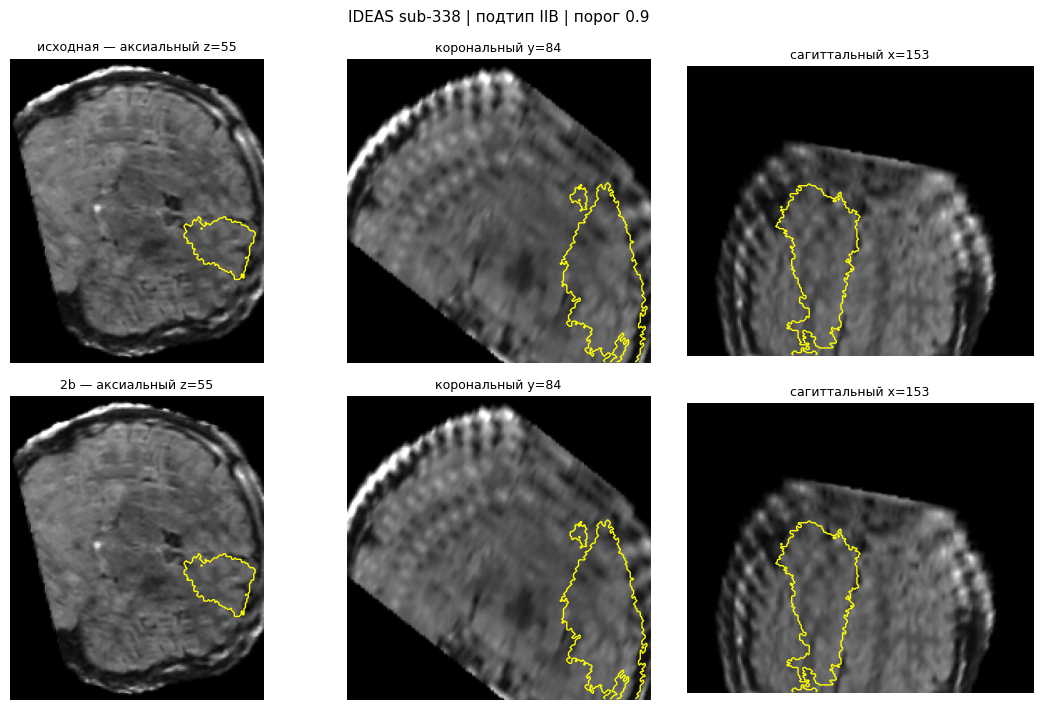

sub-338: подтип IIB, FLAIR 3.5 мм, ближайший кандидат в 36 мм от маски, макс. вероятность в мозге 1.00


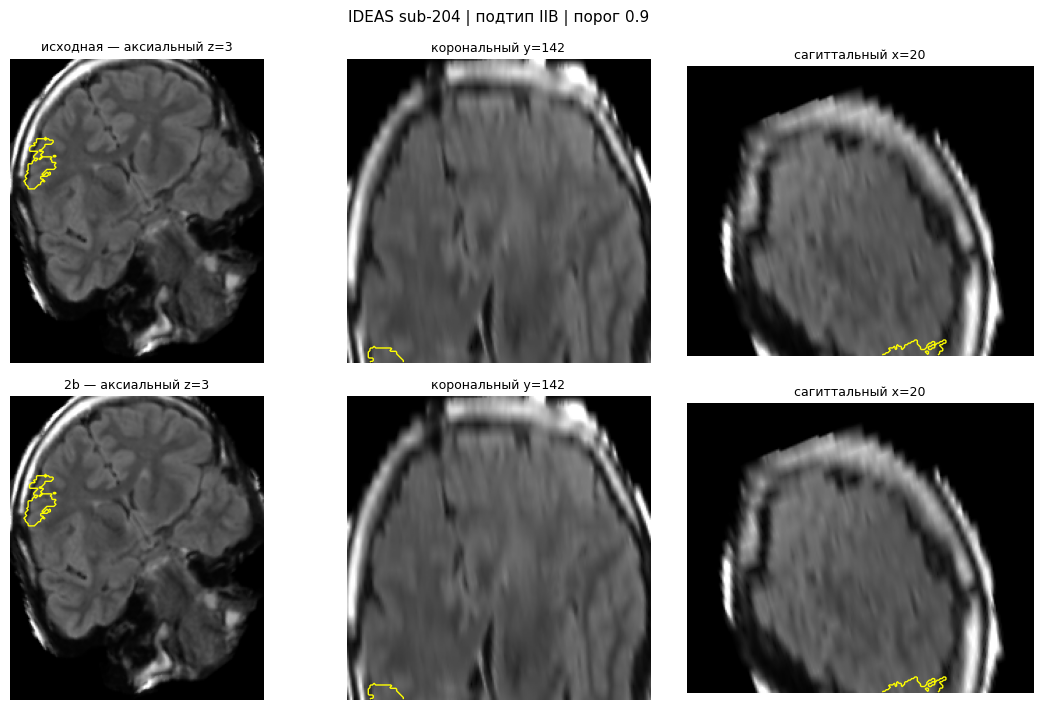

sub-204: подтип IIB, FLAIR 5.0 мм, ближайший кандидат в 75 мм от маски, макс. вероятность в мозге 1.00


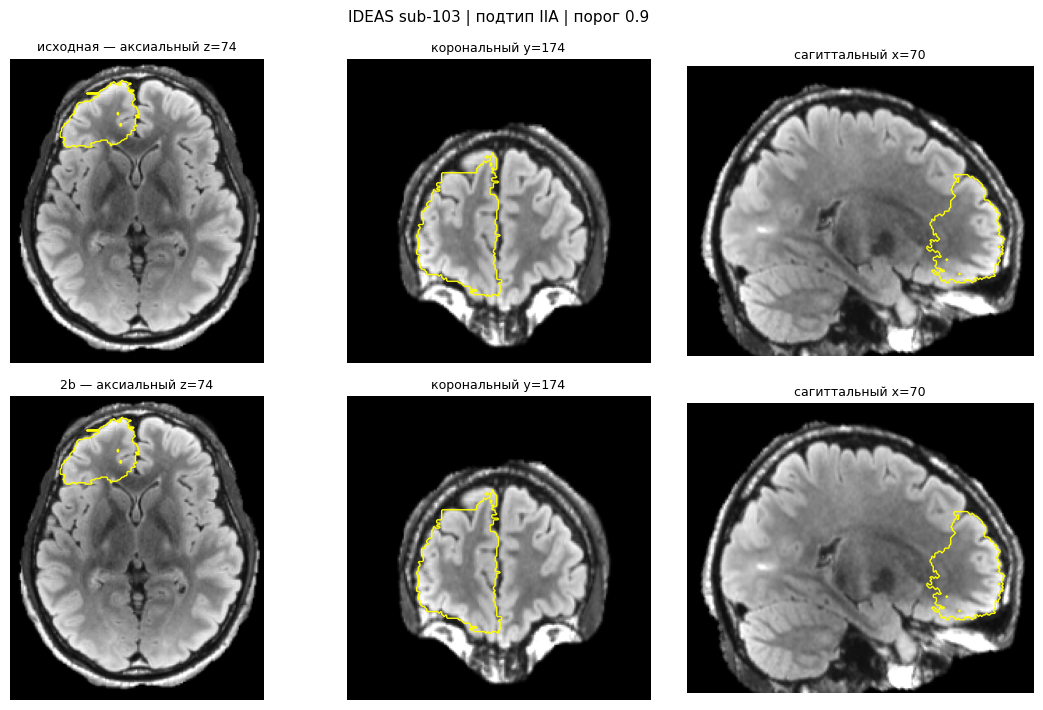

sub-103: подтип IIA, FLAIR 1.0 мм, ближайший кандидат в nan мм от маски, макс. вероятность в мозге 0.99


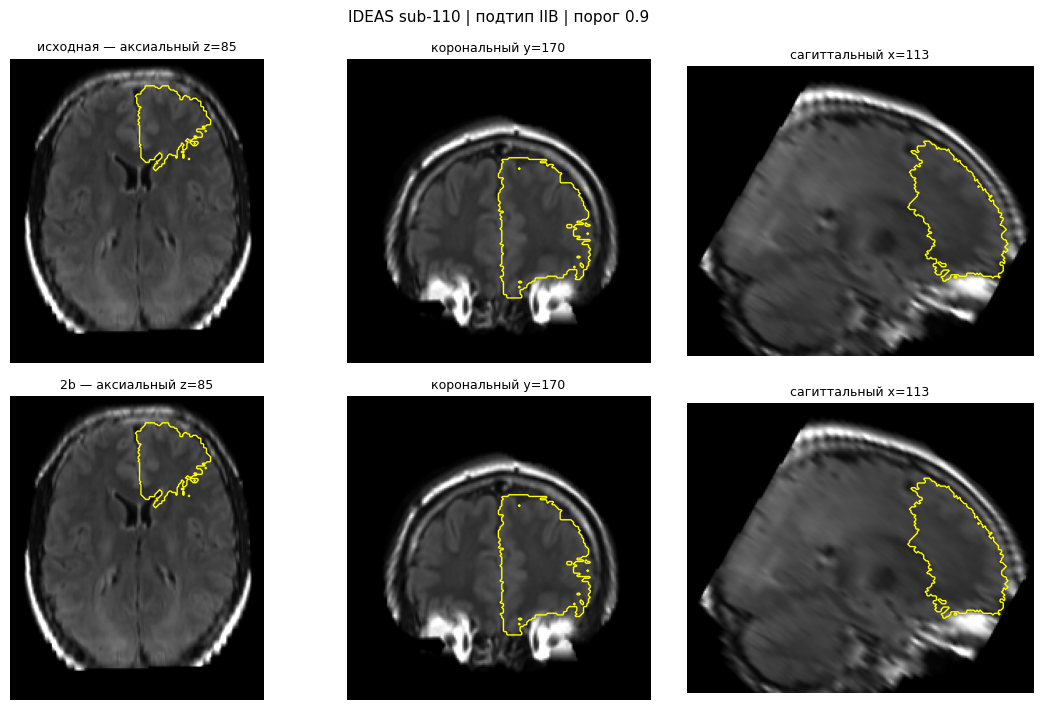

sub-110: подтип IIB, FLAIR 5.0 мм, ближайший кандидат в nan мм от маски, макс. вероятность в мозге 0.95


In [12]:
for s in miss.sort_values("dist_mm")["sub"].head(6):
    r = ev_fcd.set_index("sub").loc[s]
    compare(IDEAS, s, {"исходная": "pred", "2b": "cv2b_nyul_tta"})
    print(f"{s}: подтип {r.подтип}, FLAIR {r.FLAIR_мм:.1f} мм, ближайший кандидат в {r.dist_mm:.0f} мм от маски, "
          f"макс. вероятность в мозге {r.max_prob:.2f}")

### 4b. Ложные срабатывания у людей без ФКД (итоговый ансамбль)

Без ложных: 84% | в среднем 0.16 на человека


,n_пациентов,ложных_в_среднем
patho,,
CAV,2,0.00
DNT,3,0.67
DUAL,3,0.33
HS,15,0.13
OTHER,7,0.29
здоровый,15,0.00


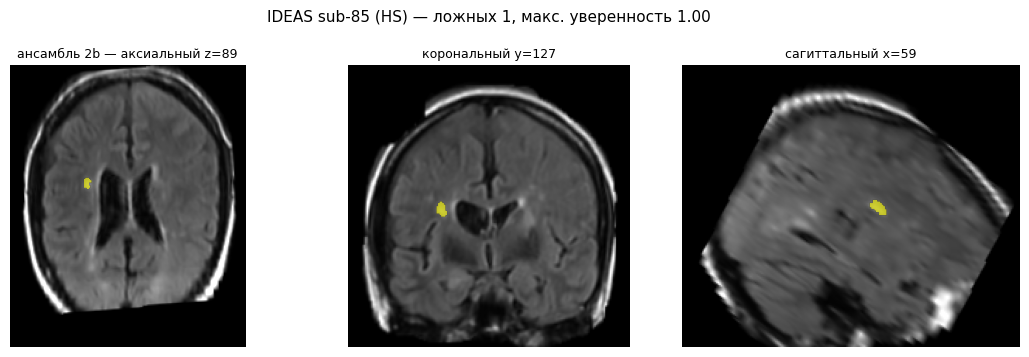

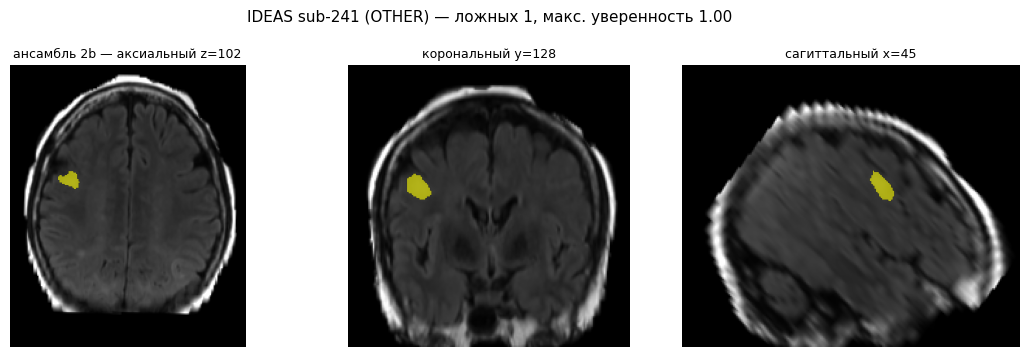

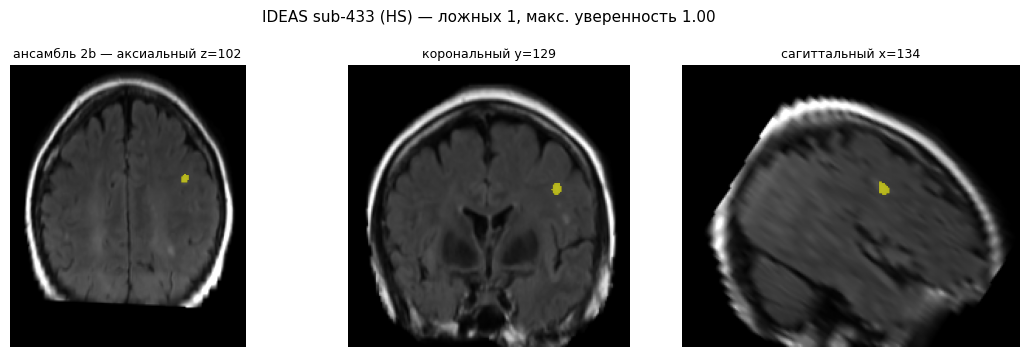

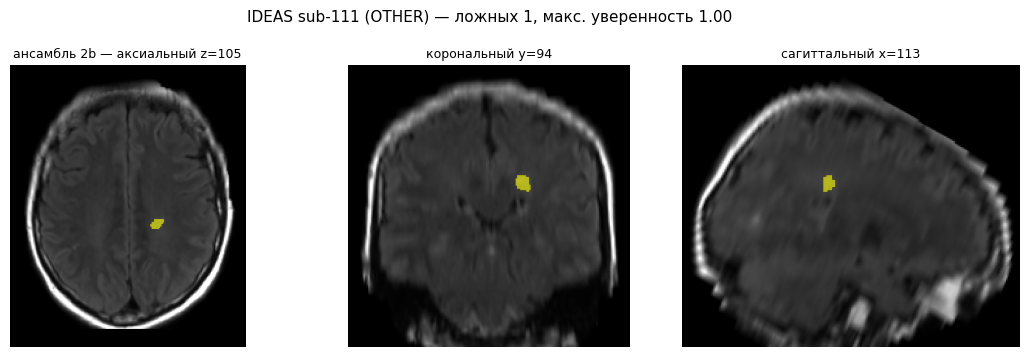

In [13]:
rows = []
for ds, s in NEG:
    fl, _, brain, aff, prob = load_case(ds, s, "ens2b")
    if prob is None: continue
    t = ml.cluster_table(prob, brain, POST, aff)
    rows.append(dict(src=ds.name, sub=s, patho=meta.loc[s, "Pathology"] if ds is IDEAS else "здоровый",
                     n=len(t), peak=t.peak_prob.max() if len(t) else 0, FLAIR_мм=flair_mm(ds, s)))
neg_df = pd.DataFrame(rows).sort_values(["n", "peak"], ascending=False)
print(f"Без ложных: {(neg_df.n == 0).mean():.0%} | в среднем {neg_df.n.mean():.2f} на человека")
display(neg_df.groupby("patho").agg(n_пациентов=("sub", "size"), ложных_в_среднем=("n", "mean")).round(2))
for _, r in neg_df[neg_df.n > 0].head(4).iterrows():
    ds = IDEAS if r.src == "IDEAS" else UHB
    fl, _, brain, aff, prob = load_case(ds, r["sub"], "ens2b")
    t = ml.cluster_table(prob, brain, POST, aff)
    view(fl, {"ансамбль 2b": post_mask(prob, brain)}, None, center=np.round(t[["vx", "vy", "vz"]].values[0]).astype(int),
         title=f"{r.src} {r['sub']} ({r.patho}) — ложных {r.n}, макс. уверенность {r.peak:.2f}")

### 4c. Пациенты с ФКД, у которых больше всего лишних кандидатов

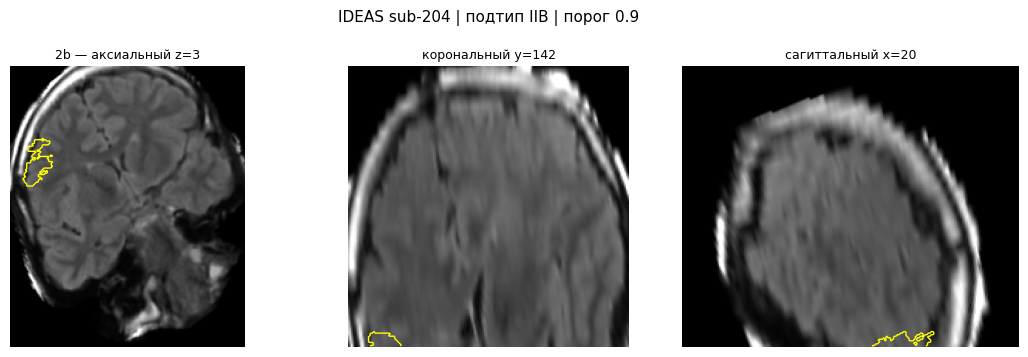

sub-204 {'исход': 'только ложные кандидаты', 'nFPC': 3, 'FLAIR_мм': 5.0, 'подтип': 'IIB'}


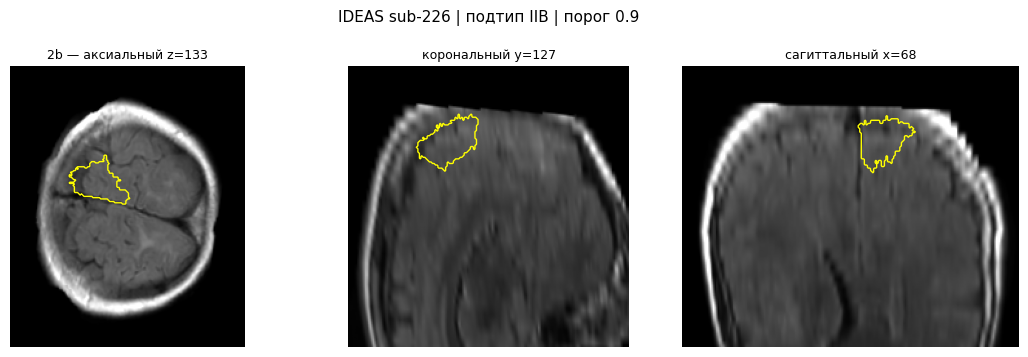

sub-226 {'исход': 'только ложные кандидаты', 'nFPC': 2, 'FLAIR_мм': 4.9997944831848145, 'подтип': 'IIB'}


In [14]:
for s in ev_fcd.sort_values("nFPC", ascending=False)["sub"].head(2):
    compare(IDEAS, s, {"2b": "cv2b_nyul_tta"})
    print(s, ev_fcd.set_index("sub").loc[s, ["исход", "nFPC", "FLAIR_мм", "подтип"]].to_dict())

# Часть 5. Итоговые цифры

In [15]:
P2 = [POST]
def fcd_row(v):
    e = ml.evaluate(IDEAS.pred(v), IDEAS.ref, FCD, P2); s = ml.summarize(e).iloc[0]; return s
def neg_row(vi, vu):
    n = []
    for ds, s in NEG:
        v = vi if ds is IDEAS else vu
        pf = ds.pred(v) / f"{s}_prob.nii.gz"
        if pf.exists(): n.append(ml.evaluate(ds.pred(v), ds.ref, [s], P2, use_gt=False).n_clusters.iloc[0])
    n = np.array(n); return n.mean(), (n == 0).mean()
tab = []
for name, vf, (vi, vu) in [("исходная", "pred", ("pred", "base")), ("Nyúl+TTA (без обучения)", "nyul_tta", ("nyul_tta", "nyul_tta")),
                           ("2b: модель фолда (ФКД) / ансамбль (без ФКД)", "cv2b_nyul_tta", ("ens2b", "ens2b"))]:
    s = fcd_row(vf); fp, spec = neg_row(vi, vu)
    tab.append({"вариант": name, "находит очаг": f"{s.sSens:.0%}", "очаг первым": f"{s.top1:.0%}", "очаг в топ-3": f"{s.top3:.0%}",
                "ложных у ФКД": round(s.nFPC, 2), "ложных без ФКД": round(fp, 2), "без ложных (без ФКД)": f"{spec:.0%}"})
print(f"Порог {THR}, маска мозга, кластеры ≥100 мм³ | ФКД n={len(FCD)} (CV) | без ФКД n={len(NEG)} (отложенные)")
display(pd.DataFrame(tab).set_index("вариант"))

Порог 0.9, маска мозга, кластеры ≥100 мм³ | ФКД n=34 (CV) | без ФКД n=45 (отложенные)


,находит очаг,очаг первым,очаг в топ-3,ложных у ФКД,ложных без ФКД,без ложных (без ФКД)
вариант,,,,,,
исходная,29%,18%,29%,0.79,0.49,58%
Nyúl+TTA (без обучения),38%,38%,38%,0.15,0.09,91%
2b: модель фолда (ФКД) / ансамбль (без ФКД),56%,50%,56%,0.35,0.16,84%
